In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
from sklearn.model_selection import train_test_split

os.makedirs("plots", exist_ok=True)  # all figures are saved here for the README

In [62]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

# Download from UCI; fall back to a local copy committed to the repo if there is no internet
try:
    df = pd.read_csv(url, header=None, names=columns)
except Exception:
    df = pd.read_csv("data_banknote_authentication.txt", header=None, names=columns)

df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [63]:
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

Shape: (1372, 5)

Data types:
variance    float64
skewness    float64
curtosis    float64
entropy     float64
class         int64
dtype: object

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Duplicate rows:
24

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


In [64]:
#checking duplicates

duplicates = df[df.duplicated(keep=False)]

duplicates = duplicates.sort_values(
    by=df.columns.tolist()
)

display(duplicates)

,variance,skewness,curtosis,entropy,class
227,-2.6479,10.1374,-1.3310,-5.4707,0
604,-2.6479,10.1374,-1.3310,-5.4707,0
727,-2.6479,10.1374,-1.3310,-5.4707,0
107,-1.8584,7.8860,-1.6643,-1.8384,0
195,-1.8584,7.8860,-1.6643,-1.8384,0
345,-1.8584,7.8860,-1.6643,-1.8384,0
219,-1.3000,10.2678,-2.9530,-5.8638,0
284,-1.3000,10.2678,-2.9530,-5.8638,0
427,-1.3000,10.2678,-2.9530,-5.8638,0
45,-0.7869,9.5663,-3.7867,-7.5034,0


In [65]:
duplicate_counts = (
    df.value_counts()
    .reset_index(name="count")
    .query("count > 1")
    .sort_values("count", ascending=False)
)

display(duplicate_counts)

,variance,skewness,curtosis,entropy,class,count
0,0.3292,-4.4552,4.5718,-0.9888,0,4
1,0.3798,0.7098,0.7572,-0.4444,0,4
2,0.5195,-3.2633,3.0895,-0.9849,0,4
3,0.5706,-0.0248,1.2421,-0.5621,0,4
4,-1.3000,10.2678,-2.9530,-5.8638,0,3
5,-0.2062,9.2207,-3.7044,-6.8103,0,3
6,-2.6479,10.1374,-1.3310,-5.4707,0,3
7,-1.8584,7.8860,-1.6643,-1.8384,0,3
8,0.9297,-3.7971,4.6429,-0.2957,0,3
9,-0.2780,8.1881,-3.1338,-2.5276,0,2


In [66]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1348, 5)


The dataset contained 24 duplicate records and no missing values. Exact duplicate records were removed before train-test splitting to avoid identical observations appearing in both sets. This resulted in 1,348 unique observations. Since no unique observation IDs were available, the duplicates could not be conclusively identified as data-entry errors.

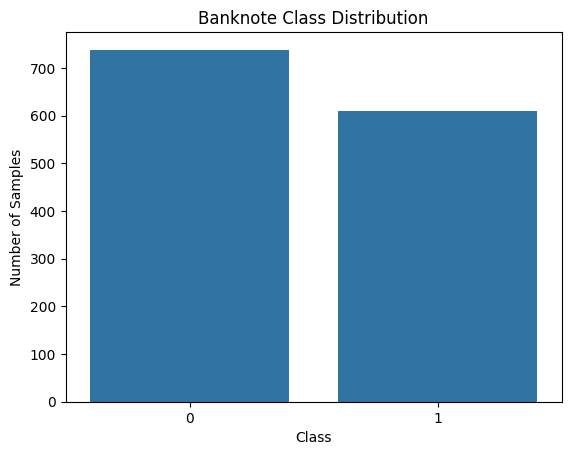

In [67]:
sns.countplot(data=df, x="class")
plt.title("Banknote Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.show()

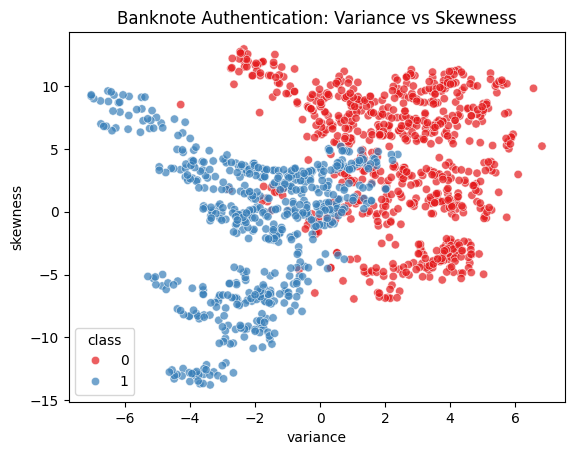

In [68]:
sns.scatterplot(
    data=df,
    x="variance",
    y="skewness",
    hue="class",
    palette="Set1",
    alpha=0.7
)

plt.title("Banknote Authentication: Variance vs Skewness")
plt.show()

In [69]:
X = df.drop(columns="class")
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1078
Testing samples: 270


In [70]:
features_2d = ["variance", "skewness"]

X_train_2d = X_train[features_2d].to_numpy()
X_test_2d = X_test[features_2d].to_numpy()

y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

print("2D training shape:", X_train_2d.shape)
print("2D testing shape:", X_test_2d.shape)

2D training shape: (1078, 2)
2D testing shape: (270, 2)


In [71]:
X_train_4d = X_train.to_numpy()
X_test_4d = X_test.to_numpy()

print("4D training shape:", X_train_4d.shape)
print("4D testing shape:", X_test_4d.shape)

4D training shape: (1078, 4)
4D testing shape: (270, 4)


In [72]:
assert X_train_2d.shape[1] == 2
assert X_train_4d.shape[1] == 4

assert not np.isnan(X_train_4d).any()
assert not np.isnan(X_test_4d).any()

assert set(np.unique(y_train_np)) == {0, 1}

print("Data preparation successful.")

Data preparation successful.


In [73]:
#gini and entropy

def gini_impurity(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)

def entropy(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))

In [74]:
def split_data(X, y, feature_index, threshold):

    left_mask = X[:, feature_index] <= threshold
    right_mask = ~left_mask

    X_left = X[left_mask]
    y_left = y[left_mask]

    X_right = X[right_mask]
    y_right = y[right_mask]

    return X_left, y_left, X_right, y_right

def weighted_impurity(y_left, y_right, criterion="gini"):

    n_left = len(y_left)
    n_right = len(y_right)
    n_total = n_left + n_right

    if n_total == 0:
        return 0.0

    impurity_fn = gini_impurity if criterion == "gini" else entropy

    return (
        (n_left / n_total) * impurity_fn(y_left)
        + (n_right / n_total) * impurity_fn(y_right)
    )

def find_best_split(X, y, criterion="gini"):

    if criterion not in ("gini", "entropy"):
        raise ValueError("criterion must be 'gini' or 'entropy'")

    n_samples, n_features = X.shape

    best_feature = None
    best_threshold = None
    best_impurity = float("inf")

    for feature_index in range(n_features):

        unique_values = np.unique(X[:, feature_index])

        thresholds = (
            unique_values[:-1] / 2
            + unique_values[1:] / 2
        )

        for threshold in thresholds:

            X_left, y_left, X_right, y_right = split_data(
                X, y, feature_index, threshold
            )

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            impurity = weighted_impurity(
                y_left, y_right, criterion
            )

            if impurity < best_impurity:
                best_impurity = impurity
                best_feature = feature_index
                best_threshold = threshold

    return best_feature, best_threshold, best_impurity

In [75]:
X_sample = np.array([
    [1.0, 5.0],
    [2.0, 4.0],
    [3.0, 3.0],
    [4.0, 2.0],
    [5.0, 1.0]
])

y_sample = np.array([0, 0, 0, 1, 1])

feature, threshold, impurity = find_best_split(
    X_sample, y_sample, criterion="gini"
)

print("Best feature:", feature)
print("Best threshold:", threshold)
print("Weighted impurity:", impurity)

Best feature: 0
Best threshold: 3.5
Weighted impurity: 0.0


In [76]:
feature, threshold, impurity = find_best_split(
    X_train_2d,
    y_train_np,
    criterion="gini"
)

print("Best feature:", features_2d[feature])
print("Best threshold:", threshold)
print("Weighted Gini:", impurity)
print("Parent Gini:", gini_impurity(y_train_np))
print(
    "Gini reduction:",
    gini_impurity(y_train_np) - impurity
)

Best feature: variance
Best threshold: 0.7602949999999999
Weighted Gini: 0.2348590295659534
Parent Gini: 0.49552355939846005
Gini reduction: 0.26066452983250665


In [77]:
X_left, y_left, X_right, y_right = split_data(
    X_train_2d,
    y_train_np,
    feature,
    threshold
)

print("Left class counts:", np.bincount(y_left))
print("Right class counts:", np.bincount(y_right))

print("Left Gini:", gini_impurity(y_left))
print("Right Gini:", gini_impurity(y_right))

print("Total samples:", len(y_left) + len(y_right))

Left class counts: [116 451]
Right class counts: [474  37]
Left Gini: 0.3254605911866346
Right Gini: 0.1343285296854715
Total samples: 1078


In [78]:
class ManualDecisionTree:

    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    def _impurity(self, y):
        if self.criterion == "gini":
            return gini_impurity(y)
        return entropy(y)

    def _build_tree(self, X, y, depth=0):

        values, counts = np.unique(y, return_counts=True)
        predicted_class = values[np.argmax(counts)]

        node = {
            "samples": len(y),
            "class_counts": dict(zip(values.tolist(), counts.tolist())),
            "prediction": int(predicted_class),
            "impurity": float(self._impurity(y))
        }

        # Stop if node is pure, too small, or depth limit reached
        if (
            len(values) == 1
            or len(y) < self.min_samples_split
            or (self.max_depth is not None and depth >= self.max_depth)
        ):
            return node

        # Find the best feature and threshold
        feature, threshold, split_impurity = find_best_split(
            X, y, criterion=self.criterion
        )

        if feature is None:
            return node

        # Stop if no improvement in impurity
        if node["impurity"] - split_impurity <= 1e-12:
            return node

        X_left, y_left, X_right, y_right = split_data(
            X, y, feature, threshold
        )

        if len(y_left) == 0 or len(y_right) == 0:
            return node

        # Store the decision rule and construct children
        node["feature"] = int(feature)
        node["threshold"] = float(threshold)

        node["left"] = self._build_tree(
            X_left, y_left, depth + 1
        )

        node["right"] = self._build_tree(
            X_right, y_right, depth + 1
        )

        return node

    def fit(self, X, y):

        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if X.ndim != 2 or y.ndim != 1:
            raise ValueError("X must be 2D and y must be 1D")

        if len(X) != len(y) or len(y) == 0:
            raise ValueError("X and y must have matching, nonzero samples")

        self.tree = self._build_tree(X, y)
        return self

    def _predict_one(self, x, node):

        if "feature" not in node:
            return node["prediction"]

        if x[node["feature"]] <= node["threshold"]:
            return self._predict_one(x, node["left"])

        return self._predict_one(x, node["right"])

    def predict(self, X):

        if self.tree is None:
            raise ValueError("Train the model before predicting")

        X = np.asarray(X, dtype=float)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array")

        return np.array([
            self._predict_one(x, self.tree)
            for x in X
        ])

In [79]:
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=3,
    min_samples_split=2
)

manual_tree.fit(X_train_2d, y_train_np)

print("Manual Decision Tree trained.")

Manual Decision Tree trained.


In [80]:
root = manual_tree.tree

print("Root feature:", features_2d[root["feature"]])
print("Root threshold:", root["threshold"])
print("Root impurity:", root["impurity"])
print("Root samples:", root["samples"])
print("Root class counts:", root["class_counts"])

Root feature: variance
Root threshold: 0.7602949999999999
Root impurity: 0.49552355939846005
Root samples: 1078
Root class counts: {0: 590, 1: 488}


In [81]:
def print_tree(node, feature_names, depth=0):

    indent = "    " * depth

    if "feature" not in node:
        print(
            f"{indent}Predict class {node['prediction']} "
            f"(samples={node['samples']}, "
            f"impurity={node['impurity']:.4f})"
        )
        return

    feature_name = feature_names[node["feature"]]
    threshold = node["threshold"]

    print(f"{indent}IF {feature_name} <= {threshold:.4f}:")
    print_tree(node["left"], feature_names, depth + 1)

    print(f"{indent}ELSE ({feature_name} > {threshold:.4f}):")
    print_tree(node["right"], feature_names, depth + 1)

In [82]:
print_tree(manual_tree.tree, features_2d)

IF variance <= 0.7603:
    IF skewness <= 5.1608:
        IF variance <= -0.3620:
            Predict class 1 (samples=356, impurity=0.0651)
        ELSE (variance > -0.3620):
            Predict class 1 (samples=97, impurity=0.3507)
    ELSE (skewness > 5.1608):
        IF variance <= -3.4311:
            Predict class 1 (samples=32, impurity=0.0605)
        ELSE (variance > -3.4311):
            Predict class 0 (samples=82, impurity=0.0241)
ELSE (variance > 0.7603):
    IF variance <= 1.7994:
        IF skewness <= 4.8979:
            Predict class 0 (samples=75, impurity=0.4892)
        ELSE (skewness > 4.8979):
            Predict class 0 (samples=51, impurity=0.0000)
    ELSE (variance > 1.7994):
        IF variance <= 2.3921:
            Predict class 0 (samples=58, impurity=0.1576)
        ELSE (variance > 2.3921):
            Predict class 0 (samples=327, impurity=0.0000)


In [83]:
y_pred_manual = manual_tree.predict(X_test_2d)

print("First 10 predictions:", y_pred_manual[:10])
print("First 10 actual labels:", y_test_np[:10])

First 10 predictions: [0 1 0 0 1 1 0 0 0 1]
First 10 actual labels: [0 1 0 0 1 0 0 0 0 1]


In [84]:


train_predictions = manual_tree.predict(X_train_2d)

train_accuracy = np.mean(
    train_predictions == y_train_np
)

accuracy_manual = np.mean(y_pred_manual == y_test_np)


print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {accuracy_manual:.4f}")

Training Accuracy: 0.9323
Testing Accuracy: 0.9333


In [85]:
def visualize_tree(tree, feature_names):

    fig, ax = plt.subplots(figsize=(16, 8))
    ax.axis("off")

    def draw_node(node, x, y, width):

        if "feature" not in node:
            label = (
                f"Class = {node['prediction']}\n"
                f"Samples = {node['samples']}\n"
                f"Impurity = {node['impurity']:.3f}"
            )
            color = "#D5E8D4"
        else:
            label = (
                f"{feature_names[node['feature']]} "
                f"<= {node['threshold']:.3f}\n"
                f"Samples = {node['samples']}\n"
                f"Impurity = {node['impurity']:.3f}"
            )
            color = "#DAE8FC"

        ax.text(
            x, y, label,
            ha="center",
            va="center",
            fontsize=9,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor=color,
                edgecolor="black"
            )
        )

        if "feature" in node:

            left_x = x - width / 2
            right_x = x + width / 2
            child_y = y - 1

            ax.plot([x, left_x], [y, child_y], "k-", alpha=0.5)
            ax.plot([x, right_x], [y, child_y], "k-", alpha=0.5)

            draw_node(node["left"], left_x, child_y, width / 2)
            draw_node(node["right"], right_x, child_y, width / 2)

    draw_node(tree, 0, 0, 4)

    ax.relim()
    ax.autoscale_view()
    ax.margins(0.15)

    plt.title("Manual Decision Tree")
    plt.savefig("manual_tree.png", dpi=300, bbox_inches="tight")
    plt.show()

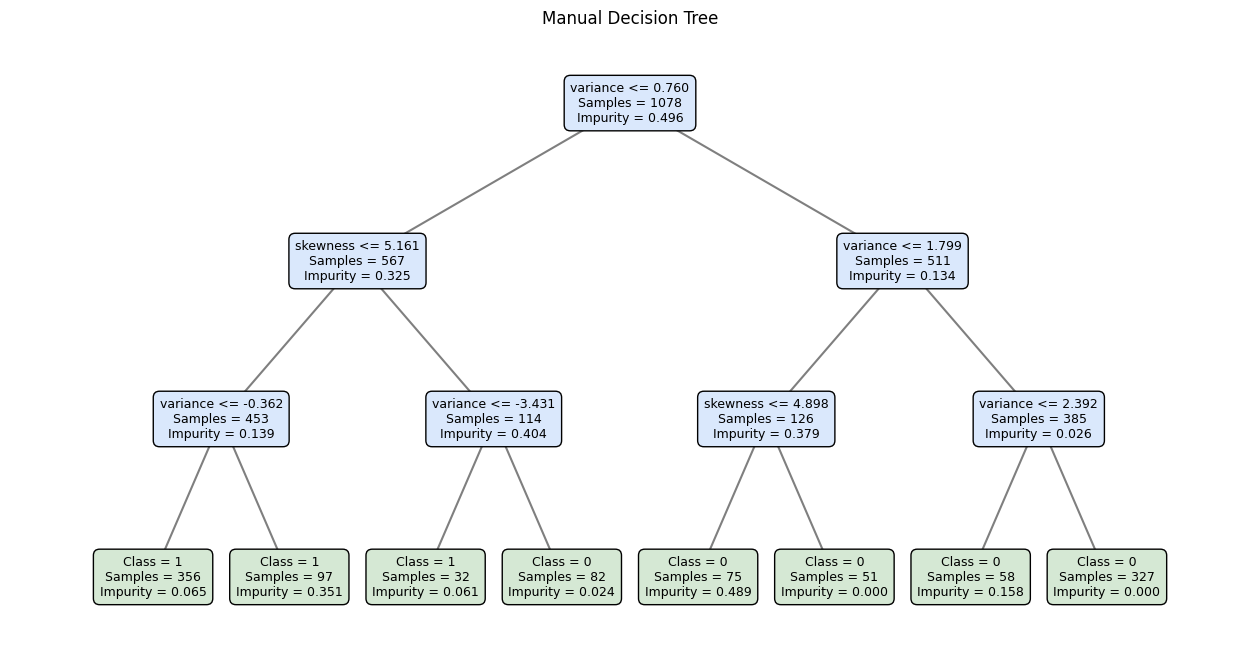

In [86]:
visualize_tree(manual_tree.tree, features_2d)

In [87]:
from matplotlib.colors import ListedColormap

def plot_decision_boundary(model, X, y, title, filename=None):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx, yy, predictions,
        levels=[-0.5, 0.5, 1.5],
        cmap=ListedColormap(["#A6CEE3", "#FDBF6F"]),
        alpha=0.5
    )

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap=ListedColormap(["#1F78B4", "#FF7F00"]),
        edgecolor="black",
        linewidth=0.3,
        s=25
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    if filename:
        plt.savefig(f"plots/{filename}", dpi=200, bbox_inches="tight")
    plt.show()

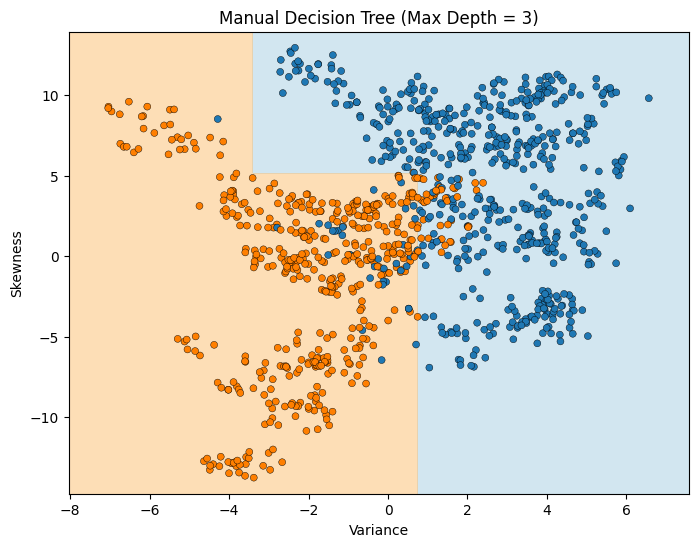

In [88]:
plot_decision_boundary(
    manual_tree,
    X_train_2d,
    y_train_np,
    "Manual Decision Tree (Max Depth = 3)",
    "tree_manual_boundary_depth3.png"
)

In [89]:
depth_results = []

for depth in [1, 2, 3, 5, 10]:

    model = ManualDecisionTree(
        criterion="gini",
        max_depth=depth
    )

    model.fit(X_train_2d, y_train_np)

    train_acc = np.mean(
        model.predict(X_train_2d) == y_train_np
    )

    test_acc = np.mean(
        model.predict(X_test_2d) == y_test_np
    )

    depth_results.append({
        "Depth": depth,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc
    })

depth_df = pd.DataFrame(depth_results)

display(depth_df)

,Depth,Train Accuracy,Test Accuracy
0,1,0.858071,0.837037
1,2,0.904453,0.900000
2,3,0.932282,0.933333
3,5,0.950835,0.937037
4,10,0.988868,0.929630


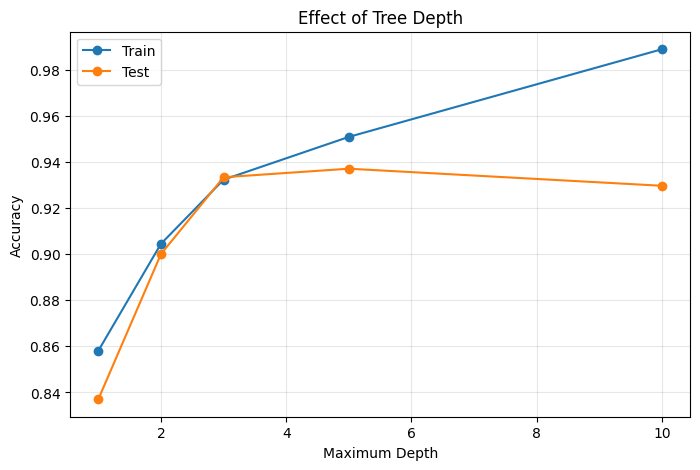

In [90]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_df["Depth"],
    depth_df["Train Accuracy"],
    marker="o",
    label="Train"
)

plt.plot(
    depth_df["Depth"],
    depth_df["Test Accuracy"],
    marker="o",
    label="Test"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("plots/tree_depth_effect_manual.png", dpi=200, bbox_inches="tight")
plt.show()

In [91]:
from sklearn.tree import DecisionTreeClassifier

sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=2,
    random_state=42
)

sklearn_tree.fit(X_train_2d, y_train_np)

print("Scikit-learn Decision Tree trained.")

Scikit-learn Decision Tree trained.


In [92]:
from sklearn.metrics import accuracy_score

manual_pred = manual_tree.predict(X_test_2d)
sklearn_pred = sklearn_tree.predict(X_test_2d)

manual_acc = accuracy_score(y_test_np, manual_pred)
sklearn_acc = accuracy_score(y_test_np, sklearn_pred)

agreement = np.mean(manual_pred == sklearn_pred)

print(f"Manual Tree Accuracy: {manual_acc:.4f}")
print(f"Scikit-learn Tree Accuracy: {sklearn_acc:.4f}")
print(f"Prediction Agreement: {agreement:.4f}")

Manual Tree Accuracy: 0.9333
Scikit-learn Tree Accuracy: 0.9333
Prediction Agreement: 1.0000


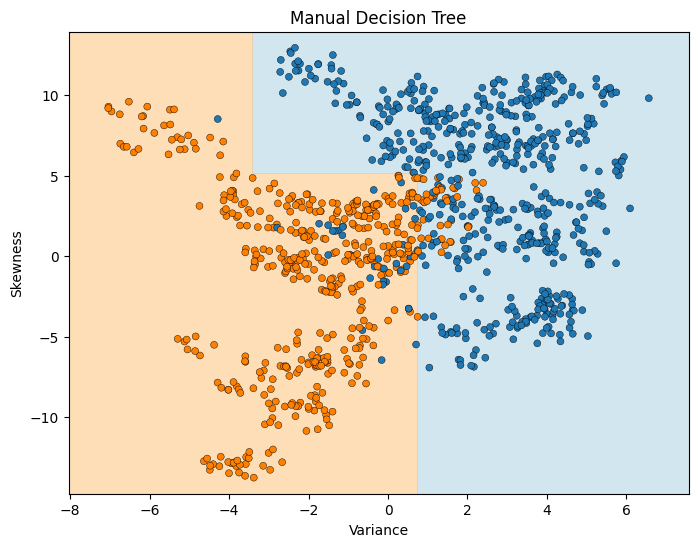

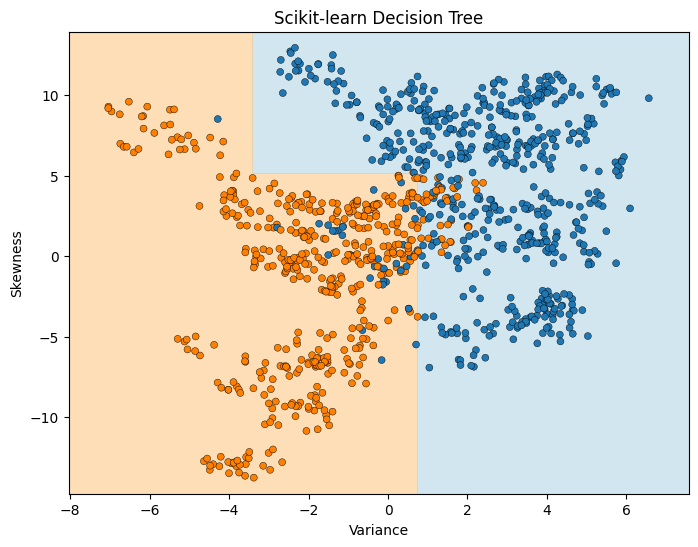

In [93]:
plot_decision_boundary(
    manual_tree,
    X_train_2d,
    y_train_np,
    "Manual Decision Tree",
    "tree_manual_boundary.png"
)

plot_decision_boundary(
    sklearn_tree,
    X_train_2d,
    y_train_np,
    "Scikit-learn Decision Tree",
    "tree_sklearn_boundary.png"
)

In [94]:
root_feature = sklearn_tree.tree_.feature[0]
root_threshold = sklearn_tree.tree_.threshold[0]

print("Manual root feature:",
      features_2d[manual_tree.tree["feature"]])

print("Manual root threshold:",
      manual_tree.tree["threshold"])

print("Sklearn root feature:",
      features_2d[root_feature])

print("Sklearn root threshold:",
      root_threshold)

Manual root feature: variance
Manual root threshold: 0.7602949999999999
Sklearn root feature: variance
Sklearn root threshold: 0.7602950036525726


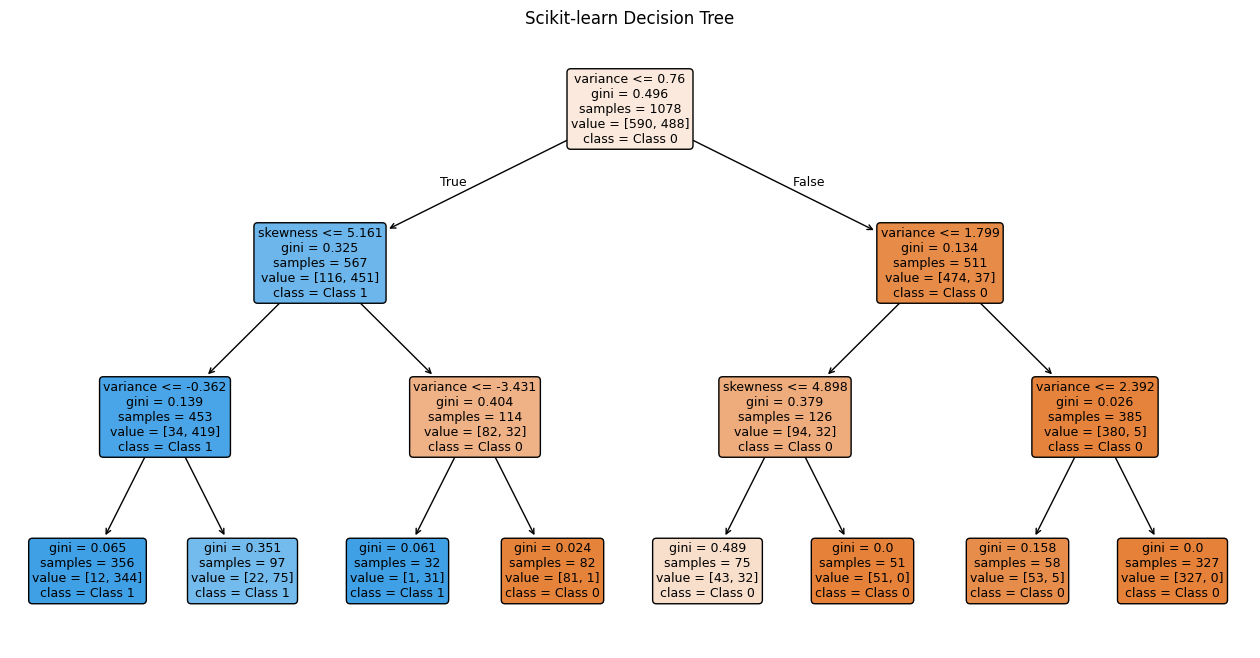

In [95]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    sklearn_tree,
    feature_names=features_2d,
    class_names=["Class 0", "Class 1"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Scikit-learn Decision Tree")
plt.savefig("plots/tree_sklearn_structure.png", dpi=200, bbox_inches="tight")
plt.show()

In [96]:
criterion_results = []

for criterion in ["gini", "entropy"]:

    manual_model = ManualDecisionTree(
        criterion=criterion,
        max_depth=3
    )

    sklearn_model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=3,
        random_state=42
    )

    manual_model.fit(X_train_2d, y_train_np)
    sklearn_model.fit(X_train_2d, y_train_np)

    criterion_results.append({
        "Criterion": criterion,
        "Manual Accuracy": accuracy_score(
            y_test_np,
            manual_model.predict(X_test_2d)
        ),
        "Sklearn Accuracy": accuracy_score(
            y_test_np,
            sklearn_model.predict(X_test_2d)
        )
    })

criterion_df = pd.DataFrame(criterion_results)

display(criterion_df)

,Criterion,Manual Accuracy,Sklearn Accuracy
0,gini,0.933333,0.933333
1,entropy,0.933333,0.933333


In [97]:
depth_comparison = []

for depth in [1, 2, 3, 5, 10]:

    manual_model = ManualDecisionTree(
        criterion="gini",
        max_depth=depth
    )

    sklearn_model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    manual_model.fit(X_train_2d, y_train_np)
    sklearn_model.fit(X_train_2d, y_train_np)

    manual_train_acc = accuracy_score(
        y_train_np,
        manual_model.predict(X_train_2d)
    )

    manual_test_acc = accuracy_score(
        y_test_np,
        manual_model.predict(X_test_2d)
    )

    sklearn_train_acc = accuracy_score(
        y_train_np,
        sklearn_model.predict(X_train_2d)
    )

    sklearn_test_acc = accuracy_score(
        y_test_np,
        sklearn_model.predict(X_test_2d)
    )

    depth_comparison.append({
        "Depth": depth,
        "Manual Train": manual_train_acc,
        "Manual Test": manual_test_acc,
        "Sklearn Train": sklearn_train_acc,
        "Sklearn Test": sklearn_test_acc
    })

depth_comparison_df = pd.DataFrame(depth_comparison)

display(depth_comparison_df)

,Depth,Manual Train,Manual Test,Sklearn Train,Sklearn Test
0,1,0.858071,0.837037,0.858071,0.837037
1,2,0.904453,0.900000,0.904453,0.900000
2,3,0.932282,0.933333,0.932282,0.933333
3,5,0.950835,0.937037,0.950835,0.937037
4,10,0.988868,0.929630,0.988868,0.933333


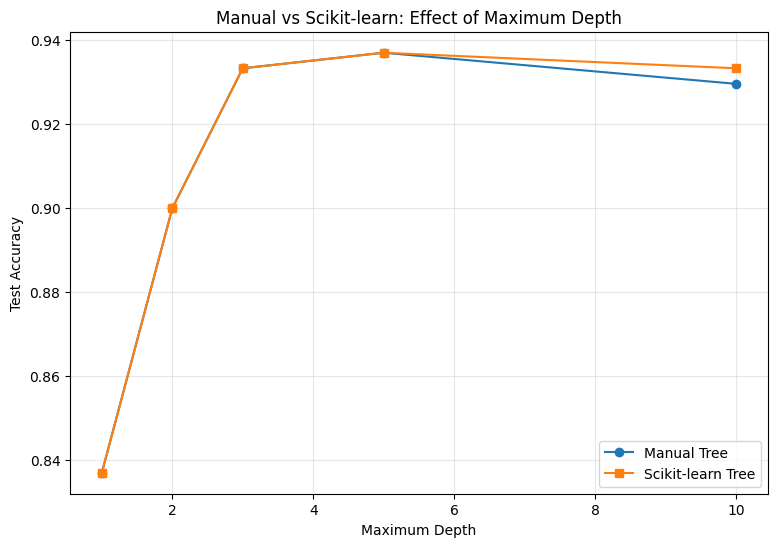

In [98]:
plt.figure(figsize=(9, 6))

plt.plot(
    depth_comparison_df["Depth"],
    depth_comparison_df["Manual Test"],
    marker="o",
    label="Manual Tree"
)

plt.plot(
    depth_comparison_df["Depth"],
    depth_comparison_df["Sklearn Test"],
    marker="s",
    label="Scikit-learn Tree"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Test Accuracy")
plt.title("Manual vs Scikit-learn: Effect of Maximum Depth")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("plots/tree_depth_manual_vs_sklearn.png", dpi=200, bbox_inches="tight")
plt.show()

**Part A observations (from the results above)**

1. **Manual vs Scikit-learn.** With the same settings (Gini, depth 3, two features) the two trees pick the same root split (`variance` at about 0.7603), give identical train and test accuracy (0.9323 / 0.9333) and agree on 100% of the test predictions. The manual implementation therefore reproduces scikit-learn. At depths 1 to 5 the two trees give identical train and test accuracy. At depth 10 the training accuracy is the same (0.9889) but the test accuracy differs by one sample (0.9296 manual vs 0.9333 scikit-learn). Deep trees contain many nodes where several splits give the same impurity, and the two implementations break those ties differently (scikit-learn also considers features in a random order).

2. **Gini vs entropy.** Both criteria gave exactly the same test accuracy (0.9333) for the manual and the scikit-learn tree at depth 3. Gini and entropy are both concave measures of impurity that peak at a 50/50 node, so on a simple two-class problem like this they usually choose very similar splits. Gini is slightly cheaper because it has no logarithm.

3. **Effect of maximum depth.** Training accuracy rises steadily with depth (0.858, 0.904, 0.932, 0.951, 0.989 for depths 1, 2, 3, 5, 10). Test accuracy rises up to depth 5 (0.937) and then falls at depth 10 (0.930). The gap between train and test grows, which means deeper trees start memorising the training data (overfitting). Depth 3 to 5 is the sensible range. Depth 1 underfits (a single threshold cannot separate the classes).


# PART B

In [99]:
mean_2d = X_train_2d.mean(axis=0)
std_2d = X_train_2d.std(axis=0)
std_2d[std_2d == 0] = 1

X_train_scaled = (X_train_2d - mean_2d) / std_2d
X_test_scaled = (X_test_2d - mean_2d) / std_2d

y_train_svm = np.where(y_train_np == 0, -1, 1)
y_test_svm = np.where(y_test_np == 0, -1, 1)

In [100]:
class ManualLinearSVM:

    def __init__(self, C=1.0, learning_rate=0.01, iterations=5000):
        self.C = C
        self.learning_rate = learning_rate
        self.iterations = iterations

    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.iterations):

            margins = y * (X @ self.w + self.b)
            violations = margins < 1

            dw = self.w - self.C * (
                X[violations].T @ y[violations]
            ) / n_samples

            db = -self.C * np.sum(y[violations]) / n_samples

            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

            margins = y * (X @ self.w + self.b)

            loss = (
                0.5 * np.dot(self.w, self.w)
                + self.C * np.maximum(0, 1 - margins).mean()
            )

            self.loss_history.append(loss)

        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

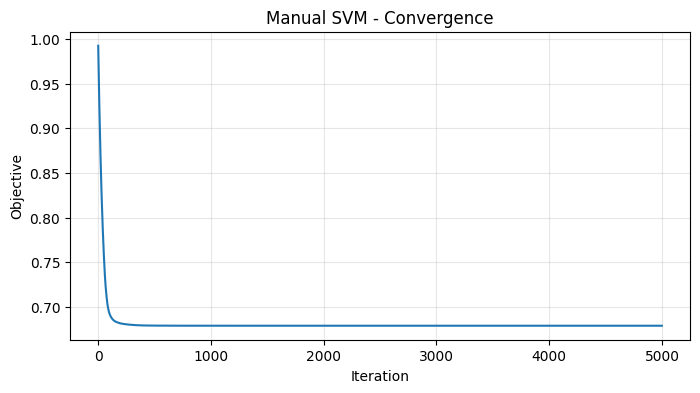

In [101]:
manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    iterations=5000
)

manual_svm.fit(X_train_scaled, y_train_svm)

plt.figure(figsize=(8, 4))
plt.plot(manual_svm.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Objective")
plt.title("Manual SVM - Convergence")
plt.grid(alpha=0.3)
plt.show()

In [102]:
from sklearn.svm import SVC
sklearn_svm = SVC(
    kernel="linear",
    C=manual_svm.C / len(y_train_svm),
    tol=1e-6
)

sklearn_svm.fit(X_train_scaled, y_train_svm)

,C,0.0009276437847866419
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,1e-06
,cache_size,200
,class_weight,None
,verbose,False


In [103]:
models = {
    "Manual SVM": manual_svm,
    "Sklearn SVM": sklearn_svm
}

results = []

for name, model in models.items():

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train_svm,
            model.predict(X_train_scaled)
        ),
        "Test Accuracy": accuracy_score(
            y_test_svm,
            model.predict(X_test_scaled)
        )
    })

pd.DataFrame(results)

,Model,Train Accuracy,Test Accuracy
0,Manual SVM,0.850649,0.885185
1,Sklearn SVM,0.850649,0.885185


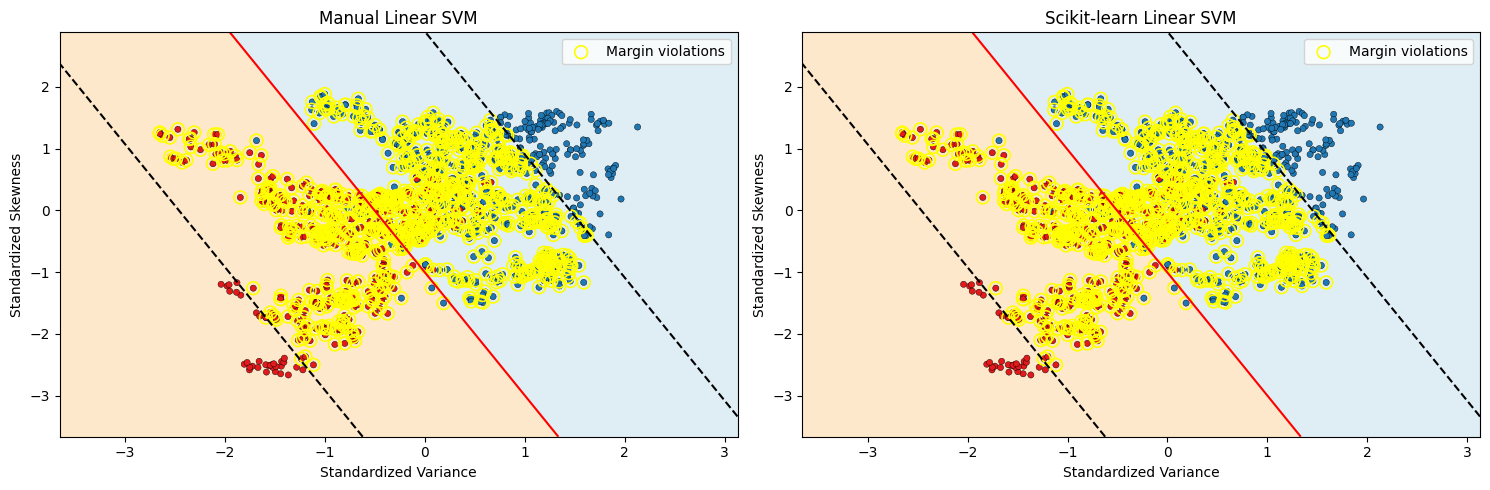

In [104]:
from matplotlib.colors import ListedColormap

def plot_svm(ax, model, X, y, title):

    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
        np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, scores,
        levels=[-np.inf, 0, np.inf],
        colors=["#A6CEE3", "#FDBF6F"],
        alpha=0.35
    )

    ax.contour(
        xx, yy, scores,
        levels=[-1, 0, 1],
        colors=["black", "red", "black"],
        linestyles=["--", "-", "--"]
    )

    ax.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap=ListedColormap(["#1F78B4", "#E31A1C"]),
        s=20,
        edgecolors="black",
        linewidths=0.3
    )

    violations = y * model.decision_function(X) < 1

    ax.scatter(
        X[violations, 0],
        X[violations, 1],
        facecolors="none",
        edgecolors="yellow",
        s=85,
        linewidths=1.2,
        label="Margin violations"
    )

    ax.set_title(title)
    ax.set_xlabel("Standardized Variance")
    ax.set_ylabel("Standardized Skewness")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_svm(
    axes[0], manual_svm,
    X_train_scaled, y_train_svm,
    "Manual Linear SVM"
)

plot_svm(
    axes[1], sklearn_svm,
    X_train_scaled, y_train_svm,
    "Scikit-learn Linear SVM"
)

plt.tight_layout()
plt.savefig("plots/svm_manual_vs_sklearn_margins.png", dpi=200, bbox_inches="tight")
plt.show()

In [105]:
experiments = {
    "C": [0.01, 0.1, 1, 10, 50],
    "learning_rate": [0.001, 0.01, 0.1, 0.5, 1.0],
    "iterations": [5, 20, 50, 100, 500, 5000]
}

experiment_results = []

for parameter, values in experiments.items():

    for value in values:

        params = {
            "C": 1.0,
            "learning_rate": 0.01,
            "iterations": 5000
        }

        params[parameter] = value

        model = ManualLinearSVM(**params)
        model.fit(X_train_scaled, y_train_svm)

        experiment_results.append({
            "Parameter": parameter,
            "Value": value,
            "Train Accuracy": accuracy_score(
                y_train_svm,
                model.predict(X_train_scaled)
            ),
            "Test Accuracy": accuracy_score(
                y_test_svm,
                model.predict(X_test_scaled)
            ),
            "Margin Width": 2 / np.linalg.norm(model.w),
            "Final Loss": model.loss_history[-1]
        })

experiment_df = pd.DataFrame(experiment_results)

display(experiment_df)


,Parameter,Value,Train Accuracy,Test Accuracy,Margin Width,Final Loss
0,C,0.010,0.547310,0.548148,232.503725,0.009918
1,C,0.100,0.547310,0.548148,23.250373,0.091824
2,C,1.000,0.850649,0.885185,3.499645,0.679002
3,C,10.000,0.887755,0.907407,1.645847,3.886130
4,C,50.000,0.884045,0.903704,1.166172,15.486070
5,learning_rate,0.001,0.859926,0.885185,3.452223,0.679137
6,learning_rate,0.010,0.850649,0.885185,3.499645,0.679002
7,learning_rate,0.100,0.850649,0.885185,3.499645,0.679002
8,learning_rate,0.500,0.850649,0.885185,3.503816,0.679003
9,learning_rate,1.000,0.790353,0.837037,6.363605,0.764274


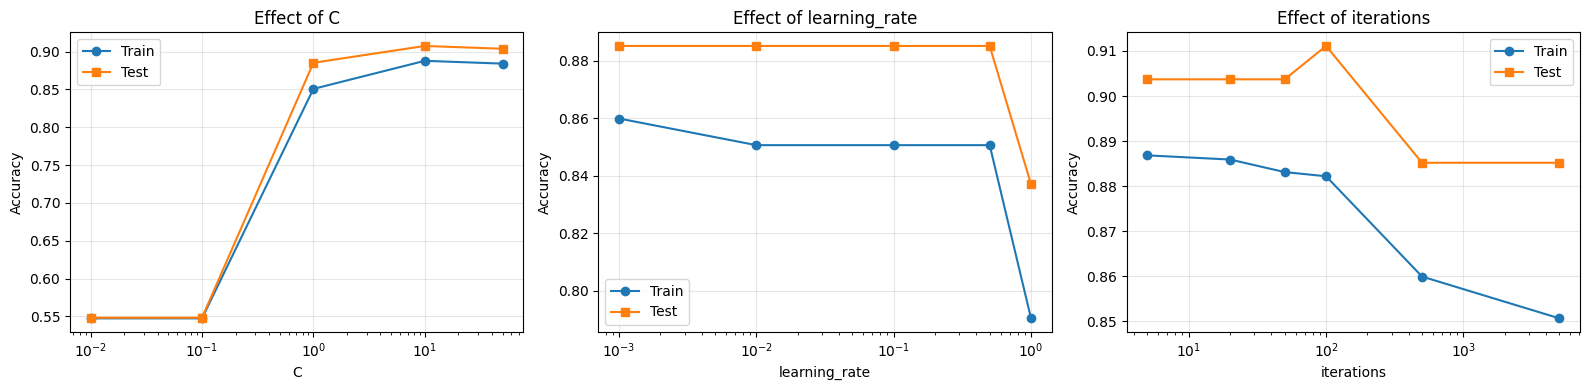

In [106]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, parameter in zip(axes, experiments):

    data = experiment_df[
        experiment_df["Parameter"] == parameter
    ]

    ax.plot(
        data["Value"],
        data["Train Accuracy"],
        marker="o",
        label="Train"
    )

    ax.plot(
        data["Value"],
        data["Test Accuracy"],
        marker="s",
        label="Test"
    )

    ax.set_xscale("log")

    ax.set_title(f"Effect of {parameter}")
    ax.set_xlabel(parameter)
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("plots/svm_hyperparameter_study.png", dpi=200, bbox_inches="tight")
plt.show()

**Part B observations**

*Manual vs Scikit-learn.* Both linear SVMs give identical train (0.8506) and test (0.8852) accuracy and essentially the same boundary and margins in the plot. To compare them fairly I matched the objectives: my loss is `0.5||w||^2 + C * mean(hinge)`, while scikit-learn minimises `0.5||w||^2 + C_sk * sum(hinge)`, so `C_sk = C / n_samples`. Using `C_sk = C` would regularise much less and the two models would not agree. With only two features a linear boundary is limited (~85-89% accuracy), so the lower score here is expected and not a bug.

*Effect of C.* C controls the trade-off between a wide margin and few margin violations.
- In the first sweep, C = 0.01 and 0.1 gave 0.547 accuracy, which is just the majority-class rate (590/1078). With my averaged loss, a small C makes the `0.5||w||^2` term dominate, so `w` shrinks towards zero, the margin width explodes (232 and 23) and the model predicts a single class (underfitting).
- C = 1 gave 0.885 test accuracy with margin width about 3.5, and C = 10 gave 0.907 with margin width about 1.6. Larger C punishes violations more, so the margin narrows and more training points are classified correctly.
- Very large C risks fitting noise and, with a constant step size, makes the subgradient updates noisier, so the extended sweep above goes up to C = 50 only.

*Learning rate and iterations.* The objective is strongly convex, so subgradient descent converges quickly. Learning rates 0.01 and 0.1 reached exactly the same solution and loss in the first sweep, and 500 iterations were already close to the 5000-iteration solution. The widened ranges above (larger learning rates, very few iterations) show where it stops being converged: with too few iterations `w` has not yet grown to its final size, and with a very large learning rate the updates overshoot and the loss curve becomes unstable. A constant step size also means the solution oscillates slightly around the optimum, a decaying step size would remove this.


# PART C

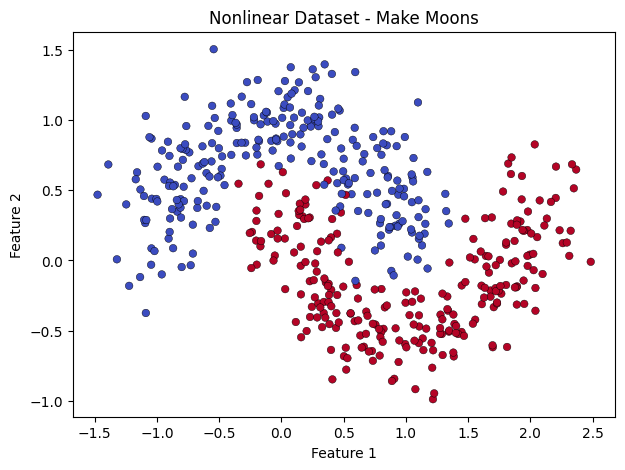

In [107]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.2,
    random_state=42
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=42,
    stratify=y_moons
)

plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="coolwarm",
    edgecolors="black",
    linewidths=0.3,
    s=30
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset - Make Moons")
plt.show()

In [108]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

kernel_models = {
    "Linear SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=1.0)
    ),

    "Polynomial SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="poly", degree=3, C=1.0, gamma="scale")
    ),

    "RBF SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    )
}

for name, model in kernel_models.items():
    model.fit(X_moons_train, y_moons_train)

print("All three SVM models trained successfully.")

All three SVM models trained successfully.


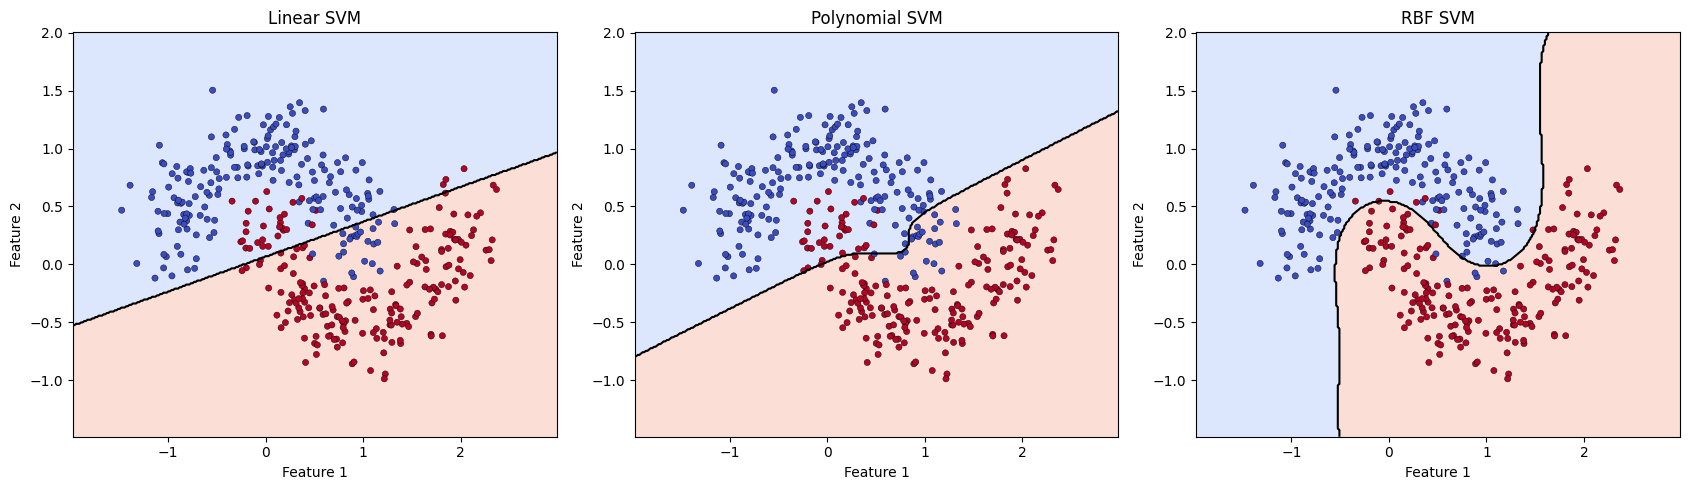

In [109]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

xx, yy = np.meshgrid(
    np.linspace(X_moons[:, 0].min() - 0.5,
                X_moons[:, 0].max() + 0.5, 300),
    np.linspace(X_moons[:, 1].min() - 0.5,
                X_moons[:, 1].max() + 0.5, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

for ax, (name, model) in zip(axes, kernel_models.items()):

    predictions = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, predictions,
        levels=[-0.5, 0.5, 1.5],
        cmap="coolwarm",
        alpha=0.3
    )

    ax.contour(
        xx, yy, predictions,
        levels=[0.5],
        colors="black",
        linewidths=1.5
    )

    ax.scatter(
        X_moons_train[:, 0],
        X_moons_train[:, 1],
        c=y_moons_train,
        cmap="coolwarm",
        edgecolors="black",
        linewidths=0.3,
        s=20
    )

    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.savefig("plots/moons_kernel_boundaries.png", dpi=200, bbox_inches="tight")
plt.show()

In [110]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

kernel_results = []

for name, model in kernel_models.items():

    y_train_pred = model.predict(X_moons_train)
    y_test_pred = model.predict(X_moons_test)

    kernel_results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_moons_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_moons_test, y_test_pred),
        "Precision": precision_score(y_moons_test, y_test_pred),
        "Recall": recall_score(y_moons_test, y_test_pred),
        "F1": f1_score(y_moons_test, y_test_pred)
    })

kernel_results_df = pd.DataFrame(kernel_results)

display(kernel_results_df.round(4))

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1
0,Linear SVM,0.8625,0.86,0.8462,0.88,0.8627
1,Polynomial SVM,0.8525,0.85,0.8571,0.84,0.8485
2,RBF SVM,0.9675,0.99,1.0000,0.98,0.9899


In [111]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in kernel_models.items():

    scores = cross_validate(
        model,
        X_moons_train,
        y_moons_train,
        cv=cv,
        scoring=["accuracy", "f1"],
        return_train_score=True
    )

    cv_results.append({
        "Model": name,
        "Train Accuracy": scores["train_accuracy"].mean(),
        "Validation Accuracy": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Validation F1": scores["test_f1"].mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,Train Accuracy,Validation Accuracy,Accuracy Std,Validation F1
0,Linear SVM,0.8594,0.8600,0.0184,0.8572
1,Polynomial SVM,0.8644,0.8675,0.0127,0.8651
2,RBF SVM,0.9650,0.9625,0.0158,0.9624


The RBF SVM achieved the highest cross-validation accuracy (96.25%) and F1-score (0.9624). Its training and validation accuracies were nearly identical, suggesting good generalization without significant overfitting. Linear and Polynomial SVMs achieved lower accuracy because they could not capture the nonlinear pattern as effectively with the chosen settings

**Why a nonlinear kernel helps (make_moons)**

The two moons interleave, so no straight line can separate them: the best linear SVM reached only about 0.86 test accuracy (0.8594 train, 0.8600 cross-validated). A kernel SVM works with an implicit mapping of the data into a higher-dimensional feature space (the kernel trick), where a linear separator in that space becomes a curved boundary in the original 2D space, without ever computing the mapping explicitly.

- **Linear kernel:** a single straight line, so it cuts through both moons and underfits.
- **Polynomial kernel (degree 3):** can bend the boundary, but a global cubic curve cannot wrap around two interlocking crescents. It scored 0.85 on the test set and 0.8675 cross-validated, barely better than linear, so it needs more tuning (degree, `coef0`, `C`) to help.
- **RBF kernel:** the decision function is a sum of Gaussian bumps centred on support vectors, so it is a local, flexible boundary that follows the shape of each moon. It reached 0.9625 cross-validated accuracy with train accuracy (0.9650) almost equal to validation accuracy, so it generalises well.

The test set here has only 100 points, so the single-split test accuracy (RBF 0.99) is noisier than the 5-fold cross-validation estimate (0.9625). I rely on the cross-validation numbers when comparing kernels.


# PART D

In [112]:
from sklearn.preprocessing import StandardScaler

scaler_4d = StandardScaler()

X_train_4d_scaled = scaler_4d.fit_transform(X_train_4d)
X_test_4d_scaled = scaler_4d.transform(X_test_4d)

In [113]:
from time import perf_counter

models_4d = {
    "Manual Decision Tree": (
        ManualDecisionTree(
            criterion="gini",
            max_depth=3
        ),
        X_train_4d,
        X_test_4d,
        y_train_np
    ),

    "Sklearn Decision Tree": (
        DecisionTreeClassifier(
            criterion="gini",
            max_depth=3,
            random_state=42
        ),
        X_train_4d,
        X_test_4d,
        y_train_np
    ),

    "Manual Linear SVM": (
        ManualLinearSVM(
            C=1.0,
            learning_rate=0.01,
            iterations=5000
        ),
        X_train_4d_scaled,
        X_test_4d_scaled,
        y_train_svm
    ),

    "Sklearn Linear SVM": (
        SVC(
            kernel="linear",
            C=1.0 / len(y_train_svm),
            tol=1e-6
        ),
        X_train_4d_scaled,
        X_test_4d_scaled,
        y_train_svm
    ),

    "RBF SVM": (
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ),
        X_train_4d_scaled,
        X_test_4d_scaled,
        y_train_svm
    )
}

trained_models = {}
timing_results = {}

for name, (model, Xtr, Xte, ytr) in models_4d.items():

    start = perf_counter()
    model.fit(Xtr, ytr)
    train_time = perf_counter() - start

    start = perf_counter()
    predictions = model.predict(Xte)
    predict_time = perf_counter() - start

    trained_models[name] = model

    timing_results[name] = {
        "predictions": predictions,
        "train_time": train_time,
        "predict_time": predict_time
    }

In [114]:
comparison_results = []

for name, result in timing_results.items():

    model, Xtr, Xte, ytr = models_4d[name]

    predictions = result["predictions"]
    train_predictions = model.predict(Xtr)

    # SVMs were trained on labels -1/+1, convert back to 0/1 for the metrics
    if "SVM" in name:
        predictions = np.where(predictions == -1, 0, 1)
        train_predictions = np.where(train_predictions == -1, 0, 1)

    comparison_results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train_np, train_predictions),
        "Accuracy": accuracy_score(y_test_np, predictions),
        "Precision": precision_score(y_test_np, predictions),
        "Recall": recall_score(y_test_np, predictions),
        "F1": f1_score(y_test_np, predictions),
        "Train Time (s)": result["train_time"],
        "Predict Time (s)": result["predict_time"]
    })

final_comparison_df = pd.DataFrame(comparison_results)

display(final_comparison_df.round(4))
final_comparison_df.round(4).to_csv("plots/final_comparison.csv", index=False)


,Model,Train Accuracy,Accuracy,Precision,Recall,F1,Train Time (s),Predict Time (s)
0,Manual Decision Tree,0.9481,0.9444,0.9084,0.9754,0.9407,1.8393,0.0005
1,Sklearn Decision Tree,0.9481,0.9444,0.9084,0.9754,0.9407,0.0051,0.0003
2,Manual Linear SVM,0.8664,0.9074,0.9533,0.8361,0.8908,0.6600,0.0000
3,Sklearn Linear SVM,0.8664,0.9074,0.9533,0.8361,0.8908,0.0285,0.0057
4,RBF SVM,0.9991,0.9963,0.9919,1.0000,0.9959,0.0073,0.0024


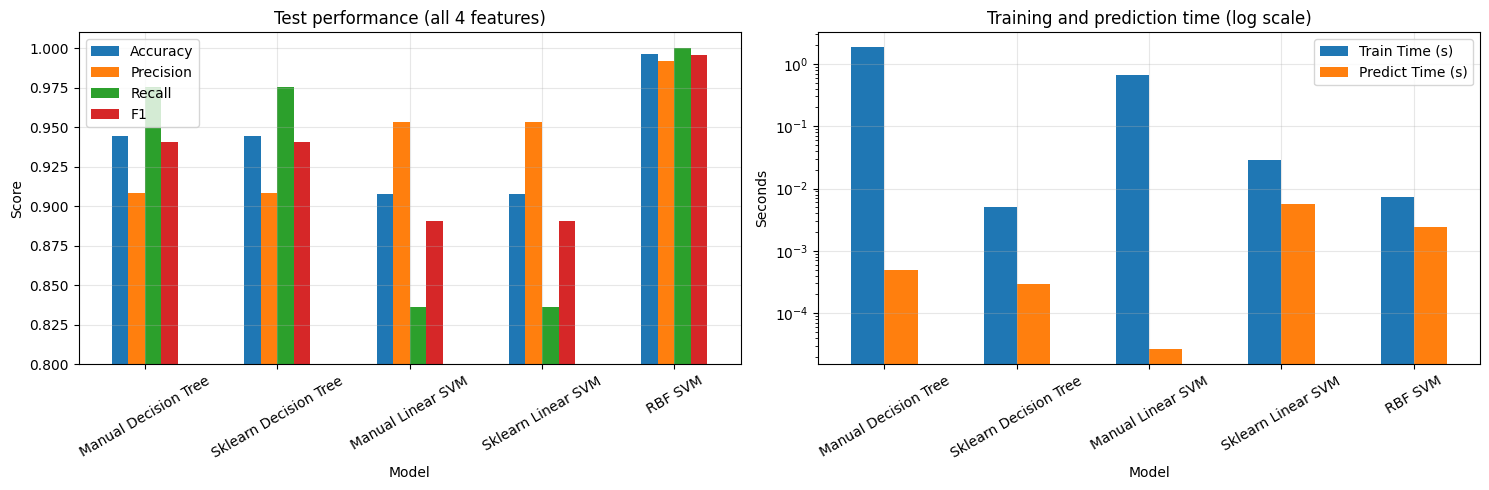

In [115]:
# Visual comparison of the four-feature results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

metrics = ["Accuracy", "Precision", "Recall", "F1"]
final_comparison_df.set_index("Model")[metrics].plot(kind="bar", ax=axes[0], ylim=(0.8, 1.01))
axes[0].set_title("Test performance (all 4 features)")
axes[0].set_ylabel("Score")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(alpha=0.3)

final_comparison_df.set_index("Model")[["Train Time (s)", "Predict Time (s)"]].plot(kind="bar", ax=axes[1], logy=True)
axes[1].set_title("Training and prediction time (log scale)")
axes[1].set_ylabel("Seconds")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("plots/final_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


In [116]:
# Quick summary read straight from the table, so the discussion below can be checked against the numbers
best = final_comparison_df.loc[final_comparison_df["Accuracy"].idxmax()]
fastest_train = final_comparison_df.loc[final_comparison_df["Train Time (s)"].idxmin()]
slowest_train = final_comparison_df.loc[final_comparison_df["Train Time (s)"].idxmax()]
gaps = (final_comparison_df["Train Accuracy"] - final_comparison_df["Accuracy"]).round(4)

print(f"Best test accuracy : {best['Model']} ({best['Accuracy']:.4f})")
print(f"Fastest to train   : {fastest_train['Model']} ({fastest_train['Train Time (s)']:.4f} s)")
print(f"Slowest to train   : {slowest_train['Model']} ({slowest_train['Train Time (s)']:.4f} s)")
print("\nTrain - test accuracy gap per model:")
print(pd.Series(gaps.values, index=final_comparison_df["Model"]))


Best test accuracy : RBF SVM (0.9963)
Fastest to train   : Sklearn Decision Tree (0.0051 s)
Slowest to train   : Manual Decision Tree (1.8393 s)

Train - test accuracy gap per model:
Model
Manual Decision Tree     0.0036
Sklearn Decision Tree    0.0036
Manual Linear SVM       -0.0410
Sklearn Linear SVM      -0.0410
RBF SVM                  0.0028
dtype: float64


**Part D**

The table and chart above compare all five models on the same train/test split using all four features. The points below are the general behaviour of these models; the numbers above show how it plays out on this dataset.

- **Accuracy and feature count.** The 2D models in Parts A and B were limited by using only variance and skewness (about 0.93 for the tree and 0.89 for the linear SVM). Using curtosis and entropy as well gives the models more information, so the four-feature scores should be higher than in the 2D experiments. The RBF SVM can also bend its boundary, which the linear SVM cannot.
- **Manual vs scikit-learn.** The manual and scikit-learn versions of each model should score (almost) the same, since they optimise the same objective. Any difference comes from tie-breaking in the tree and from the manual SVM using a fixed number of subgradient steps instead of an exact solver.
- **Precision, recall, F1.** Class 1 is the forged-note class. Recall tells us how many of those a model catches and precision tells us how many of its alarms are real. The classes are fairly balanced (about 45% / 55%), so accuracy and F1 tell a similar story here. For a real bank, a missed forgery (low recall) is probably costlier than a false alarm.
- **Interpretability.** The decision tree is the most interpretable: every prediction is a short list of `feature <= threshold` rules that can be printed and checked by hand. A linear SVM is also readable (one weight per feature, the sign and size show each feature's influence) but only after scaling. The RBF SVM is a black box: its decision depends on many support vectors, and there are no per-feature coefficients.
- **Scaling.** The SVMs (manual, linear and RBF) are distance/margin based, so they need standardised features, computed on the training set only to avoid leakage. Trees split on one feature at a time and are unaffected by monotonic rescaling, which is why the trees use the raw features.
- **Overfitting and model complexity.** The depth experiment showed that a tree gets more complex as it grows and overfits (train accuracy keeps rising while test accuracy stops improving), so the depth limit is the main control. The linear SVM has very low complexity (4 weights and a bias), so it is stable but can underfit nonlinear structure. The RBF SVM is the most flexible; `C` and `gamma` control its complexity. The train-minus-test gap printed above is a quick overfitting check for each model.
- **Time.** The manual tree and manual SVM are written with Python loops and a fixed 5000-step descent, so they are slower to train than the optimised scikit-learn versions. Prediction is fast for every model on 270 test samples. The RBF SVM's prediction cost grows with the number of support vectors, and its training cost grows quickly with dataset size, which would matter on much larger data than this one.
